<a href="https://colab.research.google.com/github/marshallpitts/movie-recommender-svd/blob/main/notebooks/03_low_rank.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Milestone 3: Low-Rank Movie Recommendations

# Name: Marshall Pitts
# Course: MATH 344L

# This notebook compares three SVD recommendation models.
#Validation ratings are used to choose model settings, and
#the test ratings are reserved for the final evaluation.

In [2]:
import os
import subprocess
import sys

USER = "marshallpitts"
REPO = "movie-recommender-svd"

if os.path.exists(REPO):
    subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
    subprocess.run(
        [
            "git",
            "clone",
            f"https://github.com/{USER}/{REPO}.git",
            REPO,
        ],
        check=True,
    )

sys.path.insert(0, os.path.abspath(f"{REPO}/src"))

from evaluate import split_ratings, to_matrix, rmse
from models import bias_baseline

print("Project functions imported successfully.")

Project functions imported successfully.


In [3]:
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if not os.path.exists("ml-100k"):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip",
    )

    with zipfile.ZipFile("ml-100k.zip") as archive:
        archive.extractall()

ratings = pd.read_csv(
    "ml-100k/u.data",
    sep="\t",
    names=["user", "item", "rating", "time"],
)

train, test = split_ratings(ratings, seed=0)
fit, val = split_ratings(train, seed=1)

print("Total ratings:", len(ratings))
print("Fitting ratings:", len(fit))
print("Validation ratings:", len(val))
print("Test ratings:", len(test))

display(ratings.head())

Total ratings: 100000
Fitting ratings: 81200
Validation ratings: 8832
Test ratings: 9968


,user,item,rating,time
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [4]:
R_fit = to_matrix(fit)
known_fit = ~np.isnan(R_fit)

val_truth = val["rating"].to_numpy()
val_u = val["user"].to_numpy() - 1
val_i = val["item"].to_numpy() - 1

def score_at(P, rows, cols, truth):
    """Calculate RMSE at selected prediction entries."""
    pred = np.clip(P[rows, cols], 1, 5)
    return rmse(pred, truth)

print("Matrix shape:", R_fit.shape)
print("Known fitting ratings:", known_fit.sum())

Matrix shape: (943, 1682)
Known fitting ratings: 81200


In [5]:
def baseline_matrix(R):
    """Predict using the overall mean plus user and movie effects."""
    mu, b_user, b_item = bias_baseline(R)
    return mu + b_user[:, None] + b_item[None, :]

B_fit = baseline_matrix(R_fit)

baseline_val_rmse = score_at(
    B_fit,
    val_u,
    val_i,
    val_truth,
)

print(
    "Baseline validation RMSE:",
    round(baseline_val_rmse, 4),
)

Baseline validation RMSE: 0.9731


In [6]:
def rank_k(U, s, Vt, k):
    """Reconstruct a matrix using its first k singular components."""
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

In [7]:
mu_fit = np.nanmean(R_fit)

n_item = known_fit.sum(axis=0)

item_mean = np.full(
    R_fit.shape[1],
    mu_fit,
)

has_rating = n_item > 0

item_mean[has_rating] = (
    np.nansum(R_fit, axis=0)[has_rating]
    / n_item[has_rating]
)

F = np.where(
    known_fit,
    R_fit,
    item_mean[None, :],
)

U1, s1, Vt1 = np.linalg.svd(
    F,
    full_matrices=False,
)

print("Model 1 SVD finished.")
print("Missing entries remaining:", np.isnan(F).sum())

Model 1 SVD finished.
Missing entries remaining: 0


In [8]:
X_fit = np.where(
    known_fit,
    R_fit - B_fit,
    0.0,
)

U2, s2, Vt2 = np.linalg.svd(
    X_fit,
    full_matrices=False,
)

print("Model 2 SVD finished.")

Model 2 SVD finished.


In [9]:
ks = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100]

val_err1 = []
val_err2 = []

for k in ks:
    P1 = rank_k(U1, s1, Vt1, k)

    P2 = (
        rank_k(U2, s2, Vt2, k)
        + B_fit
    )

    val_err1.append(
        score_at(P1, val_u, val_i, val_truth)
    )

    val_err2.append(
        score_at(P2, val_u, val_i, val_truth)
    )

best_k1 = ks[int(np.argmin(val_err1))]
best_k2 = ks[int(np.argmin(val_err2))]

rank_results = pd.DataFrame({
    "Rank": ks,
    "Model 1 validation RMSE": val_err1,
    "Model 2 validation RMSE": val_err2,
})

display(rank_results.round(4))

print("Best Model 1 rank:", best_k1)
print("Best Model 1 validation RMSE:", round(min(val_err1), 4))

print("Best Model 2 rank:", best_k2)
print("Best Model 2 validation RMSE:", round(min(val_err2), 4))

,Rank,Model 1 validation RMSE,Model 2 validation RMSE
0,1,1.0202,0.9632
1,2,1.0063,0.9570
2,3,1.0085,0.9558
3,5,0.9976,0.9526
4,10,0.9940,0.9511
5,15,0.9934,0.9492
6,20,0.9964,0.9504
7,30,1.0008,0.9572
8,50,1.0112,0.9583
9,100,1.0221,0.9680


Best Model 1 rank: 15
Best Model 1 validation RMSE: 0.9934
Best Model 2 rank: 15
Best Model 2 validation RMSE: 0.9492


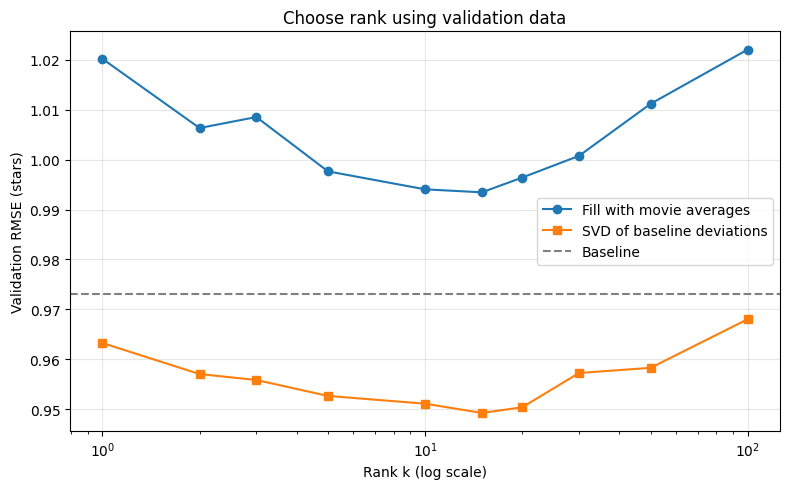

Saved graph: movie-recommender-svd/figures/validation_rmse_vs_k.png


In [10]:
figures_dir = os.path.join(REPO, "figures")
os.makedirs(figures_dir, exist_ok=True)

figure_path = os.path.join(
    figures_dir,
    "validation_rmse_vs_k.png",
)

plt.figure(figsize=(8, 5))

plt.semilogx(
    ks,
    val_err1,
    "o-",
    label="Fill with movie averages",
)

plt.semilogx(
    ks,
    val_err2,
    "s-",
    label="SVD of baseline deviations",
)

plt.axhline(
    baseline_val_rmse,
    color="gray",
    linestyle="--",
    label="Baseline",
)

plt.xlabel("Rank k (log scale)")
plt.ylabel("Validation RMSE (stars)")
plt.title("Choose rank using validation data")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(figure_path, dpi=150)
plt.show()

print("Saved graph:", figure_path)

In [11]:
def iterative_svd_predict(R, k, n_iter=10):
    """Predict ratings by repeatedly imputing missing deviations."""
    known = ~np.isnan(R)

    B = baseline_matrix(R)

    X = np.where(
        known,
        R - B,
        0.0,
    )

    for _ in range(n_iter):
        U, s, Vt = np.linalg.svd(
            X,
            full_matrices=False,
        )

        L = rank_k(U, s, Vt, k)

        X = np.where(
            known,
            R - B,
            L,
        )

    return L + B

In [12]:
ks_iter = [2, 5, 10, 20]
val_err3 = []

for k in ks_iter:
    P3 = iterative_svd_predict(
        R_fit,
        k,
        n_iter=10,
    )

    error = score_at(
        P3,
        val_u,
        val_i,
        val_truth,
    )

    val_err3.append(error)

    print(
        f"Rank {k}: validation RMSE = {error:.4f}",
        flush=True,
    )

best_k3 = ks_iter[int(np.argmin(val_err3))]

print("Best Model 3 rank:", best_k3)
print("Best Model 3 validation RMSE:", round(min(val_err3), 4))

Rank 2: validation RMSE = 0.9431
Rank 5: validation RMSE = 0.9433
Rank 10: validation RMSE = 0.9588
Rank 20: validation RMSE = 0.9769
Best Model 3 rank: 2
Best Model 3 validation RMSE: 0.9431


In [13]:
validation_summary = pd.DataFrame({
    "Model": [
        "Baseline",
        "Model 1: movie-average fill",
        "Model 2: baseline deviations",
        "Model 3: iterative SVD",
    ],
    "Selected rank": [
        None,
        best_k1,
        best_k2,
        best_k3,
    ],
    "Validation RMSE": [
        baseline_val_rmse,
        min(val_err1),
        min(val_err2),
        min(val_err3),
    ],
})

display(validation_summary.round(4))

if min(val_err3) < min(val_err2) and min(val_err3) < min(val_err1):
    chosen_model_id = 3
    chosen_model = "Iterative SVD"
    chosen_k = best_k3

elif min(val_err2) < min(val_err1):
    chosen_model_id = 2
    chosen_model = "Baseline plus low-rank deviations"
    chosen_k = best_k2

else:
    chosen_model_id = 1
    chosen_model = "SVD of movie-average-filled matrix"
    chosen_k = best_k1

print("Chosen SVD model:", chosen_model)
print("Chosen rank:", chosen_k)

,Model,Selected rank,Validation RMSE
0,Baseline,NaN,0.9731
1,Model 1: movie-average fill,15.0,0.9934
2,Model 2: baseline deviations,15.0,0.9492
3,Model 3: iterative SVD,2.0,0.9431


Chosen SVD model: Iterative SVD
Chosen rank: 2


In [14]:
## Practice Exercise 1: Does filling matter?

In [15]:
exercise_ranks = [2, 5, 10, 20]
fill_results = []

fill_matrices = {
    "Movie average": F,
    "Overall average": np.where(
        known_fit,
        R_fit,
        mu_fit,
    ),
    "3 stars": np.where(
        known_fit,
        R_fit,
        3.0,
    ),
}

for fill_name, filled_matrix in fill_matrices.items():
    if fill_name == "Movie average":
        U_fill, s_fill, Vt_fill = U1, s1, Vt1
    else:
        U_fill, s_fill, Vt_fill = np.linalg.svd(
            filled_matrix,
            full_matrices=False,
        )

    for k in exercise_ranks:
        prediction = rank_k(
            U_fill,
            s_fill,
            Vt_fill,
            k,
        )

        error = score_at(
            prediction,
            val_u,
            val_i,
            val_truth,
        )

        fill_results.append({
            "Fill": fill_name,
            "Rank": k,
            "Validation RMSE": error,
        })

fill_results = pd.DataFrame(fill_results)

display(
    fill_results.pivot(
        index="Rank",
        columns="Fill",
        values="Validation RMSE",
    ).round(4)
)

best_fill_result = fill_results.loc[
    fill_results["Validation RMSE"].idxmin()
]

print("Best result:")
print(best_fill_result)

Fill,3 stars,Movie average,Overall average
Rank,,,
2,1.1192,1.0063,1.0728
5,1.0856,0.9976,1.0568
10,1.0749,0.9940,1.0511
20,1.0788,0.9964,1.0545


Best result:
Fill               Movie average
Rank                          10
Validation RMSE         0.994048
Name: 2, dtype: object


The best filling method in my comparison was at rank 10, with validation RMSE 0.994049. Movie-average filling uses information about each movie, while overall-average and three-star filling use the same value for every gap. Filling with zero would be a poor choice because zero is outside the rating scale and could make missing ratings behave like strong negative ratings.

In [16]:
## Practice Exercise 2: Full-rank check

In [17]:
full_rank = len(s2)

full_residual = rank_k(
    U2,
    s2,
    Vt2,
    full_rank,
)

full_prediction = full_residual + B_fit

max_gap_difference = np.max(
    np.abs(
        full_prediction[~known_fit]
        - B_fit[~known_fit]
    )
)

print("Full rank:", full_rank)
print(
    "Largest difference from baseline at fitting gaps:",
    max_gap_difference,
)

Full rank: 943
Largest difference from baseline at fitting gaps: 1.865174681370263e-14


In [18]:
## Practice Exercise 3: Study iteration

In [19]:
iteration_counts = [1, 2, 5, 10]
iteration_results = []

for rounds in iteration_counts:
    prediction = iterative_svd_predict(
        R_fit,
        k=5,
        n_iter=rounds,
    )

    error = score_at(
        prediction,
        val_u,
        val_i,
        val_truth,
    )

    iteration_results.append({
        "Rounds": rounds,
        "Validation RMSE": error,
    })

    print(
        f"{rounds} rounds: validation RMSE = {error:.4f}",
        flush=True,
    )

iteration_results = pd.DataFrame(iteration_results)

display(iteration_results.round(4))

1 rounds: validation RMSE = 0.9526
2 rounds: validation RMSE = 0.9456
5 rounds: validation RMSE = 0.9411
10 rounds: validation RMSE = 0.9433


,Rounds,Validation RMSE
0,1,0.9526
1,2,0.9456
2,5,0.9411
3,10,0.9433


At rank 5, the lowest validation RMSE occurred after 5 rounds. In my results, the validation error decreased from 0.9526 at 1 round to 0.9411 at 5 rounds, then increased to 0.9433 at 10 rounds. More iterations are not guaranteed to improve validation accuracy because the estimates may increasingly fit patterns that do not generalize.

In [20]:
R_train = to_matrix(train)

test_truth = test["rating"].to_numpy()
test_u = test["user"].to_numpy() - 1
test_i = test["item"].to_numpy() - 1

B_train = baseline_matrix(R_train)

test_baseline = score_at(
    B_train,
    test_u,
    test_i,
    test_truth,
)

if chosen_model_id == 3:
    test_prediction = iterative_svd_predict(
        R_train,
        chosen_k,
        n_iter=10,
    )

elif chosen_model_id == 2:
    known_train = ~np.isnan(R_train)

    X_train = np.where(
        known_train,
        R_train - B_train,
        0.0,
    )

    U, s, Vt = np.linalg.svd(
        X_train,
        full_matrices=False,
    )

    test_prediction = (
        rank_k(U, s, Vt, chosen_k)
        + B_train
    )

else:
    known_train = ~np.isnan(R_train)
    mu_train = np.nanmean(R_train)

    n_item_train = known_train.sum(axis=0)

    means_train = np.full(
        R_train.shape[1],
        mu_train,
    )

    has_train = n_item_train > 0

    means_train[has_train] = (
        np.nansum(R_train, axis=0)[has_train]
        / n_item_train[has_train]
    )

    F_train = np.where(
        known_train,
        R_train,
        means_train[None, :],
    )

    U, s, Vt = np.linalg.svd(
        F_train,
        full_matrices=False,
    )

    test_prediction = rank_k(
        U,
        s,
        Vt,
        chosen_k,
    )

test_rmse = score_at(
    test_prediction,
    test_u,
    test_i,
    test_truth,
)

print("Chosen model:", chosen_model)
print("Chosen rank:", chosen_k)
print("Baseline test RMSE:", round(test_baseline, 4))
print("Chosen model test RMSE:", round(test_rmse, 4))

Chosen model: Iterative SVD
Chosen rank: 2
Baseline test RMSE: 0.9545
Chosen model test RMSE: 0.9286


In [21]:
item_info = pd.read_csv(
    "ml-100k/u.item",
    sep="|",
    header=None,
    usecols=[0, 1],
    encoding="latin-1",
)

item_info.columns = ["item", "title"]

user_id = 1
user_row = user_id - 1

unrated = np.where(
    np.isnan(R_train[user_row])
)[0]

predicted_scores = np.clip(
    test_prediction[user_row],
    1,
    5,
)

top = unrated[
    np.argsort(
        predicted_scores[unrated]
    )[-5:][::-1]
]

recommendations = []

for col in top:
    title = item_info.loc[
        item_info["item"] == col + 1,
        "title",
    ].iloc[0]

    recommendations.append({
        "Movie": title,
        "Predicted rating": round(
            float(predicted_scores[col]),
            2,
        ),
    })

print("Recommendations for user", user_id)

display(pd.DataFrame(recommendations))

Recommendations for user 1


,Movie,Predicted rating
0,Pulp Fiction (1994),5.0
1,"Saint of Fort Washington, The (1993)",5.0
2,"Great Day in Harlem, A (1994)",5.0
3,Santa with Muscles (1996),5.0
4,Aiqing wansui (1994),5.0


Exercise 4 — Overfitting

I selected iterative SVD with rank 2 using validation RMSE. After refitting on all training ratings, its final test RMSE was 0.9286 stars. Increasing rank does not guarantee better validation accuracy because a more complex model can fit patterns that do not generalize. The rank must be selected before looking at test performance so the test set remains an independent check. Choosing settings based on test results would make the reported performance hyperbole.

**Exercise 5 — Cold start**

For a new user with no ratings, the model cannot learn personal preferences. A fallback prediction could use the overall average plus each movie’s effect, treating the new user’s effect as zero. Asking the user to rate a few movies or identify favorite genres would help produce personalized recommendations.

**Exercise 6 — Explain the result**

The baseline test RMSE was 0.9545 stars, while iterative SVD with rank 2 achieved 0.9286 stars. The SVD model performed better because its RMSE was lower, reducing error by 0.0259 stars. The example recommendations list the highest predicted ratings among movies the user has not rated in training. They do not guarantee enjoyment, and a predicted five-star rating is still an estimate. RMSE measures rating accuracy across hidden ratings rather than directly measuring the usefulness of the recommendation list.

In [22]:
from google.colab import files

files.download(figure_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>